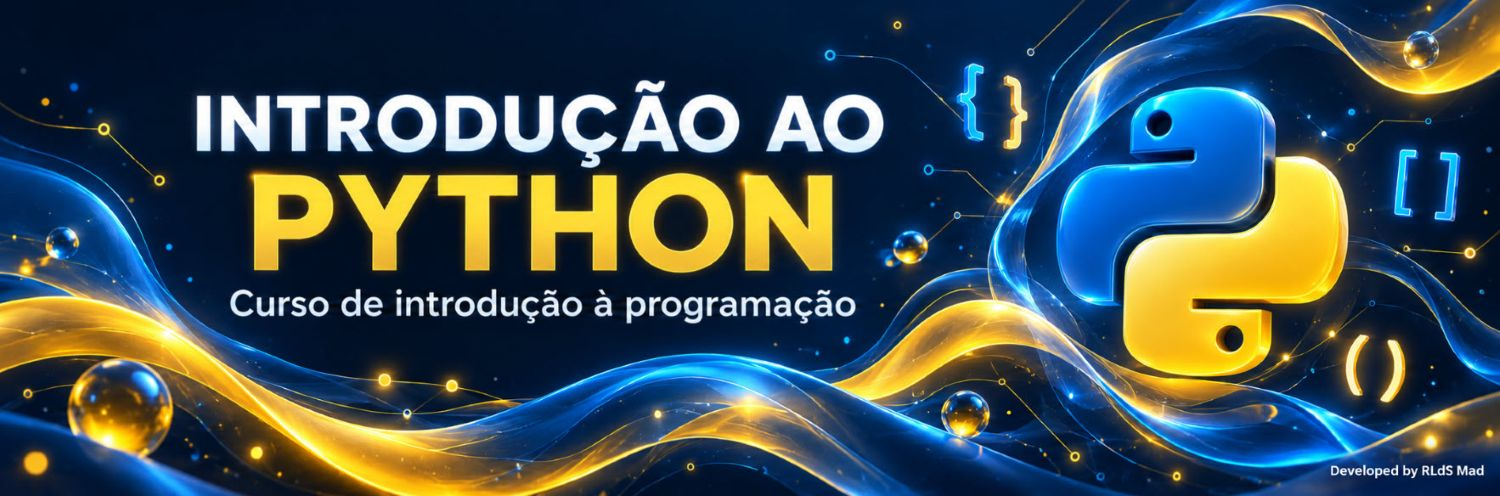

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_2_avancado/RLdS_N2_01_Pandas_Intermedio.ipynb)



# Nível avançado · Módulo 1 – Pandas na prática – dos ficheiros às decisões
### Projeto CRISP-DM

**Nível:** iniciação a intermédio. 

**Pré-requisitos:** o nível introdutório, em particular os capítulos 22 (NumPy) e 23 (Pandas básico).

**Duração sugerida:** 8–12 horas, distribuídas por sessões, mais o projeto final.



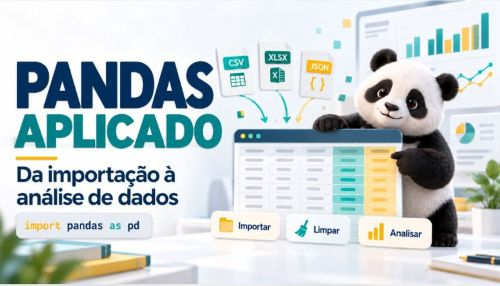


Neste percurso vais importar CSV e Excel, obter dados pela web, interpretar tabelas, detetar problemas, limpar dados, juntar fontes e comunicar resultados. Os exemplos são originais e usam uma loja fictícia portuguesa.

**Como trabalhar:** guarda este notebook numa pasta própria, escolhe o kernel Python e executa as células pela ordem apresentada (`Kernel → Restart Kernel and Run All Cells`, ou equivalente). As células criam as pastas `dados_pandas` e `resultados_pandas` no diretório de trabalho. Os ficheiros de demonstração são recriados ao executar a preparação. Não coloques ficheiros teus com os mesmos nomes nessas pastas.

O percurso principal funciona sem Internet depois de instaladas as dependências. As células de exercícios são facultativas e têm soluções no fim. As saídas incluídas mostram uma execução de referência; volta a executar para confirmar no teu ambiente.

### Índice
1. Ambiente e plano CRISP-DM
2. Series, DataFrame e índices
3. Preparação de ficheiros originais
4. Importação de CSV e Excel
5. Ficheiros e tabelas da web
6. Compreensão e diagnóstico
7. Seleção e transformação
8. Limpeza, validação e rastreabilidade
9. Junção e reformatação
10. Agregação, datas e visualização
11. Avaliação e exportação
12. Desempenho, erros frequentes e consulta rápida
13. Exercícios, soluções e projeto final


## 1. Preparar o ambiente
No Jupyter, `%pip` instala no ambiente associado ao kernel. Descomenta a linha apenas se necessário e reinicia o kernel depois da instalação. No VS Code, seleciona o mesmo ambiente em **Select Kernel**. No Colab, as pastas são temporárias: descarrega os resultados antes de terminar a sessão.

Dependências: `pandas`, `numpy`, `openpyxl` (XLSX), `matplotlib` (gráficos) e `lxml` (tabelas HTML). Os exemplos usam APIs disponíveis no Pandas 2.2 e seguintes; as versões efetivamente verificadas aparecem abaixo.


In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install "pandas>=2.2" numpy openpyxl matplotlib lxml


In [2]:
from pathlib import Path
from io import StringIO, BytesIO
import json
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 12)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")  # 2 casas decimais, sem separador de milhares
DADOS = Path.cwd() / "dados_pandas"
SAIDAS = Path.cwd() / "resultados_pandas"
DADOS.mkdir(exist_ok=True)
SAIDAS.mkdir(exist_ok=True)
print("Python:", platform.python_version(), "| Pandas:", pd.__version__)
print("Pasta de trabalho:", Path.cwd())


Python: 3.12.3 | Pandas: 3.0.6
Pasta de trabalho: /content


### CRISP-DM como fio condutor

A **mineração de dados é um processo iterativo:** podemos precisar de rever etapas anteriores à medida que surgem novas descobertas. Por exemplo, se encontrarmos preços negativos durante a limpeza, devemos voltar a investigar o significado desses valores na fonte antes de decidir como os tratar.

O **CRISP-DM** (`C`ross-`I`ndustry `S`tandard `P`rocess for `D`ata `M`ining) é uma metodologia que organiza um projeto de `mineração de dados`, desde a definição do problema até à utilização dos resultados. Pode ser aplicada em diferentes setores e com diferentes ferramentas.


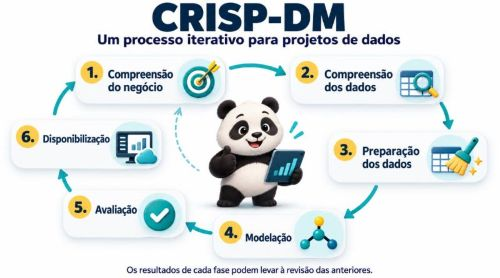


O processo de mineração de dados divide-se em seis fases:

| Fase | Aplicação neste tutorial | Resultado |
|---|---|---|
| Compreensão do negócio | Comparar vendas por mês, categoria e canal | Perguntas e regras |
| Compreensão dos dados | Interpretar linhas, unidades, tipos e qualidade | Diagnóstico inicial |
| Preparação dos dados | Corrigir formatos, tratar ausências e juntar produtos | Tabela validada |
| Modelação | Construir agregações e indicadores descritivos | Resumos e gráficos |
| Avaliação | Conferir totais, cobertura e limitações | Conclusões sustentadas |
| Disponibilização | Exportar tabelas, relatório e metadados | Entrega reproduzível |

O CRISP-DM é iterativo, as suas fases não constituem uma sequência rígida. Uma descoberta durante a análise de dados pode exigir novas fontes de dados, alterações na preparação ou uma revisão dos objetivos propostos.

Aqui, a fase de modelação limita-se à análise descritiva; não treinamos um modelo preditivo. Num projeto de aprendizagem automática seria necessário separar treino e teste **antes** de estimar imputações ou outras transformações a partir dos dados.

**Perguntas:** qual o montante líquido de vendas observadas por mês? Que categorias e canais mais contribuem? Quantas linhas não são utilizáveis e porquê?

**Unidade de observação:** uma linha de encomenda de um único produto. `id_linha` é a chave. Em dados reais, uma encomenda pode conter várias linhas; não confundir número de linhas com número de encomendas.

**Regras deste caso:** quantidade inteira positiva; preço positivo; desconto entre 0 e 0,5; data válida; produto presente no catálogo. Uma data ausente ou impossível não é inventada. Um canal vazio torna-se “Desconhecido”.

Neste módulo, o **Pandas** apoia sobretudo a compreensão e a preparação dos dados, permitindo importar ficheiros, explorar tabelas, tratar valores ausentes, corrigir formatos e produzir resumos. Num projeto apenas descritivo, podemos adaptar o percurso, sem necessidade de treinar um modelo preditivo.

## 2. Series e DataFrame

Uma `Series` é uma sequência com etiquetas; um `DataFrame` é uma tabela de colunas. O índice identifica linhas, mas não é automaticamente uma chave de negócio.


In [3]:
serie = pd.Series([12, 18, 9], index=["Lisboa", "Porto", "Faro"], name="vendas")
display(serie)
mini = pd.DataFrame({"produto": ["Caderno", "Caneta", "Mochila"],
                     "preco": [3.5, 1.2, 24.0], "stock": [80, 150, 20]})
display(mini)
print("Dimensões:", mini.shape, "| Colunas:", mini.columns.tolist())
print(type(mini["preco"]), type(mini[["preco"]]))


Lisboa    12
Porto     18
Faro       9
Name: vendas, dtype: int64

,produto,preco,stock
0,Caderno,3.50,80
1,Caneta,1.20,150
2,Mochila,24.00,20


Dimensões: (3, 3) | Colunas: ['produto', 'preco', 'stock']
<class 'pandas.Series'> <class 'pandas.DataFrame'>


## 2.1 Etiquetas, posições e alinhamento

`loc` usa etiquetas; `iloc` usa posições. Em `loc`, o fim de um intervalo de etiquetas é incluído; em `iloc`, o limite final é excluído. Pandas alinha operações por etiquetas.


In [4]:
por_produto = mini.set_index("produto")
display(por_produto.loc["Caderno":"Caneta", ["preco"]])
display(por_produto.iloc[0:2, 0:1])
a = pd.Series([10, 20], index=["A", "B"])
b = pd.Series([1, 2], index=["B", "A"])
display(pd.DataFrame({"a": a, "b": b, "soma": a + b}))
# A: 10 + 2; B: 20 + 1. Não é uma soma por posição.
display(por_produto.reset_index())


,preco
produto,
Caderno,3.50
Caneta,1.20


,preco
produto,
Caderno,3.50
Caneta,1.20


,a,b,soma
A,10,2,12
B,20,1,21


,produto,preco,stock
0,Caderno,3.50,80
1,Caneta,1.20,150
2,Mochila,24.00,20


## 3. Criar os ficheiros de treino

Esta célula cria um pequeno conjunto **sintético**, sem dados pessoais reais: `48 linhas de vendas e uma repetição exata`. Introduzimos datas impossíveis, preços inválidos, valores ausentes e códigos desconhecidos. Um conjunto maior exigiria investigação adicional; estas regras não devem ser aplicadas cegamente a outros negócios.


In [5]:
rng = np.random.default_rng(42)
n = 48
bruto = pd.DataFrame({
    "id_linha": [f"{i:05d}" for i in range(1, n+1)],
    "data": pd.date_range("2025-01-01", periods=n, freq="2D").strftime("%d/%m/%Y"),
    "produto_id": [f"P{i:02d}" for i in rng.integers(1, 5, n)],
    "cidade": rng.choice([" Lisboa ", "PORTO", "Coimbra", "Faro"], n),
    "canal": rng.choice(["loja", "ONLINE", " Online "], n),
    "quantidade": rng.integers(1, 7, n).astype(str),
    "preco_unitario": [f"{x:.2f}".replace(".", ",") for x in rng.uniform(5, 40, n)],
    "desconto": rng.choice(["0", "0,05", "0,10"], n),
    "cliente_id": [f"C{i:03d}" for i in rng.integers(1, 13, n)]
})
bruto.loc[1, "quantidade"] = ""
bruto.loc[3, "quantidade"] = "-2"
bruto.loc[4, "preco_unitario"] = "por confirmar"
bruto.loc[5, "data"] = "31/02/2025"
bruto.loc[6, "cidade"] = ""
bruto.loc[7, "desconto"] = "0,90"
bruto.loc[8, "produto_id"] = "P99"
bruto.loc[9, "canal"] = ""
bruto.loc[10, "cliente_id"] = ""
bruto.loc[11, "preco_unitario"] = "9999,00"  # valor extremo: investigar
bruto = pd.concat([bruto, bruto.iloc[[0]]], ignore_index=True)
produtos = pd.DataFrame({"produto_id": ["P01", "P02", "P03", "P04"],
                         "produto": ["Caderno", "Caneta", "Agenda", "Mochila"],
                         "categoria": ["Papelaria", "Papelaria", "Papelaria", "Acessórios"]})
metas = pd.DataFrame({"mes": ["2025-01", "2025-02", "2025-03", "2025-04"],
                      "meta_eur": [1200, 1300, 1400, 800]})
bruto.to_csv(DADOS / "vendas_pt.csv", sep=";", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(DADOS / "catalogo.xlsx", engine="openpyxl") as writer:
    produtos.to_excel(writer, sheet_name="Produtos", index=False)
    metas.to_excel(writer, sheet_name="Metas", index=False)
# Alternativas locais para a secção web
produtos.to_json(DADOS / "produtos.json", orient="records", force_ascii=False, indent=2)
(DADOS / "produtos.html").write_text(produtos.to_html(index=False), encoding="utf-8")
print("Ficheiros criados:", [p.name for p in DADOS.iterdir()])


Ficheiros criados: ['catalogo.xlsx', 'produtos.html', 'vendas_pt.csv', 'produtos.json']


### Dicionário de dados
| Coluna | Significado / tipo pretendido |
|---|---|
| id_linha | Identificador textual; preservar zeros à esquerda |
| data | Data da venda, originalmente dia/mês/ano |
| produto_id | Código para junção com o catálogo |
| cidade, canal | Dimensões de análise; texto normalizado |
| quantidade | Número inteiro positivo de unidades |
| preco_unitario | Euros por unidade, antes do desconto |
| desconto | Fração: 0,10 significa 10% |
| cliente_id | Identificador fictício; pode estar ausente |

Não há `custos, impostos, devoluções nem portes`. `“Montante líquido”` neste tutorial significa apenas `quantidade × preço × (1 - desconto)`; não significa lucro nem um valor fiscal certificado.


## 4. Importar CSV

Um CSV é texto delimitado, não um ficheiro Excel. Inspeciona primeiro o separador, a codificação e a convenção decimal. Ler identificadores como números pode destruir zeros à esquerda. `dtype="string"` preserva o conteúdo para diagnóstico.


In [6]:
print((DADOS / "vendas_pt.csv").read_text(encoding="utf-8-sig").splitlines()[:3])
vendas_raw = pd.read_csv(DADOS / "vendas_pt.csv", sep=";", encoding="utf-8-sig",
                         dtype="string", keep_default_na=True)
display(vendas_raw.head())
assert vendas_raw.loc[0, "id_linha"] == "00001"


['id_linha;data;produto_id;cidade;canal;quantidade;preco_unitario;desconto;cliente_id', '00001;01/01/2025;P01;Coimbra;loja;6;17,66;0,05;C012', '00002;03/01/2025;P04;Faro; Online ;;8,07;0,05;C004']


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
0,00001,01/01/2025,P01,Coimbra,loja,6,"17,66","0,05",C012
1,00002,03/01/2025,P04,Faro,Online,<NA>,"8,07","0,05",C004
2,00003,05/01/2025,P03,Faro,ONLINE,1,"9,13","0,10",C003
3,00004,07/01/2025,P02,Lisboa,loja,-2,"38,67",0,C012
4,00005,09/01/2025,P02,PORTO,Online,5,por confirmar,"0,10",C008


## 4.1 Decimais, ausências e importação seletiva

Num ficheiro consistente, `decimal=","` e `thousands="."` podem converter números portugueses na leitura. Se houver texto inválido, convém preservar a coluna e converter depois. `usecols` e `nrows` ajudam a explorar ficheiros grandes. `na_values` deve refletir o significado dos dados: um código “NA” pode ser legítimo.


In [7]:
amostra_csv = "codigo;valor\n001;1.234,56\n002;ND\n"
amostra = pd.read_csv(StringIO(amostra_csv), sep=";", decimal=",", thousands=".",
                       dtype={"codigo": "string"}, na_values=["ND"])
display(amostra)
display(pd.read_csv(DADOS / "vendas_pt.csv", sep=";", encoding="utf-8-sig",
                    usecols=["id_linha", "cidade"], dtype="string", nrows=4))


,codigo,valor
0,001,1234.56
1,002,NaN


,id_linha,cidade
0,00001,Coimbra
1,00002,Faro
2,00003,Faro
3,00004,Lisboa


## 4.2 Importar Excel com várias folhas

Um livro XLSX pode conter várias folhas, cabeçalhos em linhas diferentes e células de apresentação. `sheet_name=None` devolve um dicionário de DataFrames. `skiprows`, `header` e `usecols` adaptam a leitura ao ficheiro. Pandas lê tabelas; não preserva toda a formatação nem calcula fórmulas do Excel.



In [8]:
with pd.ExcelFile(DADOS / "catalogo.xlsx", engine="openpyxl") as livro:
    print("Folhas:", livro.sheet_names)
    catalogo = pd.read_excel(livro, sheet_name="Produtos", dtype="string")
    metas_lidas = pd.read_excel(livro, sheet_name="Metas", dtype={"mes": "string"})
todas_folhas = pd.read_excel(DADOS / "catalogo.xlsx", sheet_name=None, engine="openpyxl")
display(catalogo)
display(metas_lidas)


Folhas: ['Produtos', 'Metas']


,produto_id,produto,categoria
0,P01,Caderno,Papelaria
1,P02,Caneta,Papelaria
2,P03,Agenda,Papelaria
3,P04,Mochila,Acessórios


,mes,meta_eur
0,2025-01,1200
1,2025-02,1300
2,2025-03,1400
3,2025-04,800


## 5. Importar dados da web
Uma página que permite descarregar um CSV ou XLSX não é necessariamente o próprio ficheiro. Procura uma **ligação direta** ou uma API documentada. Uma resposta HTML de autenticação não pode ser lida como Excel.

O exemplo seguinte obtém um CSV público do repositório de dados de exemplo do Seaborn. Tem um limite de espera, verifica o código HTTP e guarda uma cópia. **Por defeito, a ligação externa está desligada:** o exemplo lê o CSV local e indica explicitamente essa origem. Altera `USAR_INTERNET` para `True` para experimentar. A fonte externa é independente das vendas e não entra nos seus cálculos.

Para um XLSX remoto, a sequência é a mesma: descarregar os bytes e usar `pd.read_excel(BytesIO(conteudo), engine="openpyxl")`. Não publiques tokens ou credenciais no notebook.


In [9]:
from urllib.request import Request, urlopen
from urllib.error import URLError, HTTPError
USAR_INTERNET = False
URL_CSV = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
origem_web = "CSV local de treino (ligação externa desligada)"
if USAR_INTERNET:
    try:
        pedido = Request(URL_CSV, headers={"User-Agent": "TutorialPandas/1.0"})
        with urlopen(pedido, timeout=15) as resposta:
            if resposta.status != 200:
                raise ValueError(f"Código HTTP inesperado: {resposta.status}")
            conteudo = resposta.read()
        dados_web = pd.read_csv(BytesIO(conteudo))
        if not {"species", "island"}.issubset(dados_web.columns):
            raise ValueError("Estrutura remota inesperada")
        (DADOS / "penguins_web.csv").write_bytes(conteudo)
        origem_web = URL_CSV
    except (URLError, HTTPError, TimeoutError, OSError, ValueError, pd.errors.ParserError) as erro:
        print("Não foi possível usar a fonte externa:", type(erro).__name__, str(erro))
        dados_web = vendas_raw.copy()
        origem_web = "CSV local de treino (falha da ligação externa)"
else:
    dados_web = pd.read_csv(DADOS / "vendas_pt.csv", sep=";", dtype="string", encoding="utf-8-sig")
print("Origem efetiva:", origem_web)
display(dados_web.head())


Origem efetiva: CSV local de treino (ligação externa desligada)


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
0,00001,01/01/2025,P01,Coimbra,loja,6,"17,66","0,05",C012
1,00002,03/01/2025,P04,Faro,Online,<NA>,"8,07","0,05",C004
2,00003,05/01/2025,P03,Faro,ONLINE,1,"9,13","0,10",C003
3,00004,07/01/2025,P02,Lisboa,loja,-2,"38,67",0,C012
4,00005,09/01/2025,P02,PORTO,Online,5,por confirmar,"0,10",C008


## 5.1 JSON, tabelas HTML e uma ligação HTTP local

Uma API JSON devolve normalmente objetos/listas; `json_normalize` expande estruturas aninhadas. `read_html` devolve uma **lista** de tabelas e não extrai tabelas geradas apenas por JavaScript. Esta demonstração serve ficheiros criados por nós em `127.0.0.1`, num porto atribuído pelo sistema. Não depende da Internet; se a plataforma impedir servidores locais, usa as mesmas cópias locais.


In [10]:
from http.server import ThreadingHTTPServer, SimpleHTTPRequestHandler
from functools import partial
from threading import Thread

class HandlerSilencioso(SimpleHTTPRequestHandler):
    def log_message(self, *args):
        pass

servidor = None
try:
    handler = partial(HandlerSilencioso, directory=str(DADOS))
    servidor = ThreadingHTTPServer(("127.0.0.1", 0), handler)
    Thread(target=servidor.serve_forever, daemon=True).start()
    base = f"http://127.0.0.1:{servidor.server_port}"
    with urlopen(base + "/produtos.json", timeout=5) as r:
        registos_json = json.load(r)
    with urlopen(base + "/produtos.html", timeout=5) as r:
        html = r.read().decode("utf-8")
    with urlopen(base + "/catalogo.xlsx", timeout=5) as r:
        excel_http = pd.read_excel(BytesIO(r.read()), sheet_name="Produtos", engine="openpyxl")
    print("JSON, HTML e XLSX obtidos por HTTP local.")
except OSError as erro:
    print("HTTP local indisponível; leitura das cópias locais:", erro)
    registos_json = json.loads((DADOS / "produtos.json").read_text(encoding="utf-8"))
    html = (DADOS / "produtos.html").read_text(encoding="utf-8")
    excel_http = pd.read_excel(DADOS / "catalogo.xlsx", sheet_name="Produtos")
finally:
    if servidor is not None:
        servidor.shutdown()
        servidor.server_close()
json_df = pd.json_normalize(registos_json)
tabelas_html = pd.read_html(StringIO(html))
display(json_df, tabelas_html[0], excel_http)
assert len(tabelas_html) == 1
assert len(excel_http) == 4


JSON, HTML e XLSX obtidos por HTTP local.


,produto_id,produto,categoria
0,P01,Caderno,Papelaria
1,P02,Caneta,Papelaria
2,P03,Agenda,Papelaria
3,P04,Mochila,Acessórios


,produto_id,produto,categoria
0,P01,Caderno,Papelaria
1,P02,Caneta,Papelaria
2,P03,Agenda,Papelaria
3,P04,Mochila,Acessórios


,produto_id,produto,categoria
0,P01,Caderno,Papelaria
1,P02,Caneta,Papelaria
2,P03,Agenda,Papelaria
3,P04,Mochila,Acessórios


## 5.2 Expandir JSON aninhado

Quando uma chave contém outro objeto, `json_normalize` cria colunas com nomes compostos. Para `APIs paginadas`, é ainda necessário percorrer páginas e verificar limites; esta pequena resposta não tem paginação.



In [11]:
resposta_api = [{"id": 1, "local": {"cidade": "Lisboa", "pais": "PT"}, "total": 25},
                {"id": 2, "local": {"cidade": "Porto", "pais": "PT"}, "total": 40}]
display(pd.json_normalize(resposta_api, sep="_"))


,id,total,local_cidade,local_pais
0,1,25,Lisboa,PT
1,2,40,Porto,PT


## 6. Compreender antes de limpar

`head` não substitui uma inspeção global. `info` mostra tipos e valores não nulos. Como preservámos texto, `describe` resume frequências e não estatísticas numéricas. Uma linha com campo vazio não é necessariamente uma linha inútil.



In [12]:
display(vendas_raw.head(3), vendas_raw.tail(3))
print("Linhas e colunas:", vendas_raw.shape)
vendas_raw.info()
display(vendas_raw.describe(include="all"))
diagnostico = pd.DataFrame({"tipo": vendas_raw.dtypes.astype(str),
                            "ausentes": vendas_raw.isna().sum(),
                            "percentagem_ausente": vendas_raw.isna().mean().mul(100),
                            "valores_distintos": vendas_raw.nunique(dropna=True)})
display(diagnostico)
print("Repetições exatas:", vendas_raw.duplicated().sum())
display(vendas_raw["cidade"].value_counts(dropna=False))


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
0,00001,01/01/2025,P01,Coimbra,loja,6,"17,66","0,05",C012
1,00002,03/01/2025,P04,Faro,Online,<NA>,"8,07","0,05",C004
2,00003,05/01/2025,P03,Faro,ONLINE,1,"9,13","0,10",C003


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
46,00047,03/04/2025,P02,Faro,loja,5,"37,82","0,05",C012
47,00048,05/04/2025,P04,PORTO,ONLINE,4,"25,01","0,10",C003
48,00001,01/01/2025,P01,Coimbra,loja,6,"17,66","0,05",C012


Linhas e colunas: (49, 9)
<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_linha        49 non-null     string
 1   data            49 non-null     string
 2   produto_id      49 non-null     string
 3   cidade          48 non-null     string
 4   canal           48 non-null     string
 5   quantidade      48 non-null     string
 6   preco_unitario  49 non-null     string
 7   desconto        49 non-null     string
 8   cliente_id      48 non-null     string
dtypes: string(9)
memory usage: 5.6 KB


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
count,49,49,49,48,48,48,49,49,48
unique,48,48,5,4,3,7,48,4,12
top,00001,01/01/2025,P04,PORTO,ONLINE,3,"17,66",0,C012
freq,2,2,15,15,20,10,2,19,8


,tipo,ausentes,percentagem_ausente,valores_distintos
id_linha,string,0,0.00,48
data,string,0,0.00,48
produto_id,string,0,0.00,5
cidade,string,1,2.04,4
canal,string,1,2.04,3
quantidade,string,1,2.04,7
preco_unitario,string,0,0.00,48
desconto,string,0,0.00,4
cliente_id,string,1,2.04,12


Repetições exatas: 1


cidade
PORTO       15
Faro        13
Coimbra     11
 Lisboa      9
<NA>         1
Name: count, dtype: int64[pyarrow]

## 7. Selecionar, filtrar e ordenar

`df["coluna"]` devolve uma Series; `df[["coluna"]]` mantém um DataFrame. Em máscaras, usa `&`, `|` e parênteses, em vez de `and`/`or`. Uma Series não tem um único valor de verdade.


In [13]:
display(vendas_raw.loc[:4, ["id_linha", "cidade", "produto_id"]])
display(vendas_raw.iloc[:3, :4])
mascara = (vendas_raw["produto_id"].isin(["P01", "P02"]) &
           vendas_raw["cidade"].str.contains("porto", case=False, na=False))
display(vendas_raw.loc[mascara].sort_values("data").head())
# A ordenação acima é textual: datas devem ser convertidas antes de ordenar cronologicamente.


,id_linha,cidade,produto_id
0,00001,Coimbra,P01
1,00002,Faro,P04
2,00003,Faro,P03
3,00004,Lisboa,P02
4,00005,PORTO,P02


,id_linha,data,produto_id,cidade
0,00001,01/01/2025,P01,Coimbra
1,00002,03/01/2025,P04,Faro
2,00003,05/01/2025,P03,Faro


,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id
17,00018,04/02/2025,P01,PORTO,ONLINE,4,"25,27",0,C006
19,00020,08/02/2025,P02,PORTO,ONLINE,3,"34,98","0,05",C012
4,00005,09/01/2025,P02,PORTO,Online,5,por confirmar,"0,10",C008
21,00022,12/02/2025,P02,PORTO,loja,5,"30,18",0,C011


## 7.1 Atualizar com segurança e trabalhar com texto

Evita atribuições encadeadas como `df[mascara]["canal"] = ...`. Usa `df.loc[mascara, "canal"] = ...` numa única operação. `copy` torna explícito que pretendes uma tabela independente; esta forma também se adequa à semântica Copy-on-Write do Pandas 3.


In [14]:
exemplo = vendas_raw.copy()
exemplo.columns = exemplo.columns.str.strip().str.lower()
exemplo["cidade"] = exemplo["cidade"].str.strip().str.title()
exemplo["canal"] = exemplo["canal"].str.strip().str.lower()
exemplo.loc[exemplo["canal"].eq("online"), "canal"] = "Online"
display(exemplo[["cidade", "canal"]].head())
# Expressão regular: verificar o formato do identificador.
display(exemplo["id_linha"].str.fullmatch(r"\d{5}", na=False).value_counts())


,cidade,canal
0,Coimbra,loja
1,Faro,Online
2,Faro,Online
3,Lisboa,loja
4,Porto,Online


id_linha
True    49
Name: count, dtype: Int64

## 8. Limpeza com decisões explícitas
Não vamos usar `dropna()` sobre toda a tabela nem substituir todos os vazios por zero.

| Problema | Decisão no caso de estudo |
|---|---|
| Repetição exata | Remover e registar o número |
| Mesma chave com conteúdo diferente | Interromper: precisa de resolução na origem |
| Texto inválido em números / datas | Converter para ausente e sinalizar |
| Quantidade, preço, data ou desconto inválidos | Colocar a linha em quarentena |
| Produto desconhecido | Colocar a linha em quarentena |
| Cidade ou canal ausentes | Usar “Desconhecida/o”, preservando a ausência original na tabela bruta |
| Cliente ausente | Manter: a venda pode continuar válida |
| Preço extremo | Sinalizar para revisão; não remover automaticamente |

O preço extremo fica na análise, com aviso. Não existe uma fonte que autorize corrigi-lo. Isto mostrará como um único valor pode influenciar uma conclusão.


In [15]:
def converter_decimal_pt(serie):
    """Converter texto com vírgula decimal; inválidos tornam-se NA/NaN."""
    texto = serie.astype("string").str.strip().str.replace("€", "", regex=False)
    texto = texto.str.replace(" ", "", regex=False)
    texto = texto.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

def preparar_vendas(raw, catalogo):
    df = raw.drop_duplicates().copy()
    if df["id_linha"].isna().any() or df["id_linha"].duplicated().any():
        raise ValueError("Chave ausente ou repetida com conteúdo diferente: resolver na origem.")
    df["data"] = pd.to_datetime(df["data"], format="%d/%m/%Y", errors="coerce")
    df["quantidade"] = pd.to_numeric(df["quantidade"], errors="coerce")
    for coluna in ["preco_unitario", "desconto"]:
        df[coluna] = converter_decimal_pt(df[coluna])
    df["cidade"] = df["cidade"].str.strip().str.title().fillna("Desconhecida")
    df["canal"] = df["canal"].str.strip().str.lower().fillna("desconhecido")
    regras = pd.DataFrame({
        "data_invalida": df["data"].isna(),
        "quantidade_invalida": (df["quantidade"].isna() | df["quantidade"].le(0) |
                                  df["quantidade"].mod(1).ne(0)),
        "preco_invalido": df["preco_unitario"].isna() | df["preco_unitario"].le(0),
        "desconto_invalido": ~df["desconto"].between(0, 0.5).fillna(False),
        "produto_desconhecido": ~df["produto_id"].isin(catalogo["produto_id"])
    }).fillna(True)
    invalida = regras.any(axis=1)
    quarentena = raw.loc[df.index[invalida]].copy()
    quarentena["motivos"] = regras.loc[invalida].apply(
        lambda linha: "; ".join(linha.index[linha]), axis=1)
    limpo = df.loc[~invalida].copy()
    limpo["quantidade"] = limpo["quantidade"].astype("Int64")
    limpo["canal"] = limpo["canal"].astype("category")
    limpo["montante_bruto"] = limpo["quantidade"] * limpo["preco_unitario"]
    limpo["montante_liquido"] = limpo["montante_bruto"] * (1 - limpo["desconto"])
    # Limite didático de triagem, não uma prova de erro.
    limpo["rever_preco"] = limpo["preco_unitario"].gt(500)
    auditoria = {"linhas_origem": len(raw), "duplicados_exatos": int(raw.duplicated().sum()),
                 "linhas_quarentena": len(quarentena), "linhas_validas": len(limpo)}
    return limpo, quarentena, regras, auditoria

vendas, quarentena, regras, auditoria = preparar_vendas(vendas_raw, catalogo)
display(pd.Series(auditoria, name="contagem"), quarentena)
display(regras.sum().rename("linhas_por_problema"))
# Uma linha pode ter mais do que um problema: somar motivos pode contar a mesma linha várias vezes.
display(vendas.head())


linhas_origem        49
duplicados_exatos     1
linhas_quarentena     6
linhas_validas       42
Name: contagem, dtype: int64

,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id,motivos
1,00002,03/01/2025,P04,Faro,Online,<NA>,"8,07","0,05",C004,quantidade_invalida
3,00004,07/01/2025,P02,Lisboa,loja,-2,"38,67",0,C012,quantidade_invalida
4,00005,09/01/2025,P02,PORTO,Online,5,por confirmar,"0,10",C008,preco_invalido
5,00006,31/02/2025,P04,PORTO,loja,1,"29,49",0,C004,data_invalida
7,00008,15/01/2025,P03,Lisboa,loja,2,"38,92","0,90",C007,desconto_invalido
8,00009,17/01/2025,P99,Coimbra,Online,6,"32,26","0,10",C011,produto_desconhecido


data_invalida           1
quantidade_invalida     2
preco_invalido          1
desconto_invalido       1
produto_desconhecido    1
Name: linhas_por_problema, dtype: Int64

,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id,montante_bruto,montante_liquido,rever_preco
0,00001,2025-01-01,P01,Coimbra,loja,6,17.66,0.05,C012,105.96,100.66,False
2,00003,2025-01-05,P03,Faro,online,1,9.13,0.10,C003,9.13,8.22,False
6,00007,2025-01-13,P01,Desconhecida,online,6,14.31,0.05,C008,85.86,81.57,False
9,00010,2025-01-19,P01,Lisboa,desconhecido,2,30.09,0.05,C004,60.18,57.17,False
10,00011,2025-01-21,P03,Coimbra,online,3,20.73,0.00,<NA>,62.19,62.19,False


### Entender as conversões
`errors="coerce"` transforma conteúdo inválido em `NaN`, `pd.NA` ou `NaT`, conforme o tipo. É uma ferramenta de diagnóstico, não uma correção automática. O bruto e a quarentena permitem recuperar o texto original.

A função decimal pressupõe a convenção portuguesa: `1.234,56` significa 1234,56. Não a uses numa coluna de texto com ponto decimal (`12.50`), porque removeria o ponto. Primeiro identifica a convenção da fonte.

`Int64` com I maiúsculo permite inteiros com `pd.NA`; `int64` NumPy não aceita ausências. `category` é útil para um conjunto limitado de valores, mas novas categorias devem ser adicionadas antes de uma atribuição.


## 8.1 Valores ausentes: três estratégias

Eliminar exige justificação; imputar altera os dados; manter pode ser a opção mais honesta. A mediana seguinte é apenas uma demonstração isolada e não é aplicada às vendas. Comparar `x == np.nan` não deteta ausências: usa `isna()`.


In [16]:
medicoes = pd.DataFrame({"grupo": ["A", "A", "B", "B"], "tempo": [10, None, 30, 40]})
medicoes["tempo_mediana_global"] = medicoes["tempo"].fillna(medicoes["tempo"].median())
medicoes["tempo_mediana_grupo"] = medicoes["tempo"].fillna(
    medicoes.groupby("grupo")["tempo"].transform("median"))
display(medicoes)
display(medicoes.dropna(subset=["tempo"]))
print("Clientes ausentes em vendas válidas:", vendas["cliente_id"].isna().sum())


,grupo,tempo,tempo_mediana_global,tempo_mediana_grupo
0,A,10.00,10.00,10.00
1,A,NaN,30.00,10.00
2,B,30.00,30.00,30.00
3,B,40.00,40.00,40.00


,grupo,tempo,tempo_mediana_global,tempo_mediana_grupo
0,A,10.00,10.00,10.00
2,B,30.00,30.00,30.00
3,B,40.00,40.00,40.00


Clientes ausentes em vendas válidas: 1


## 8.2 Verificações de qualidade

Uma tabela limpa deve cumprir contratos verificáveis. As asserções interrompem a execução se uma condição falhar. Aqui confirmamos também a reconciliação de linhas e a estabilidade da função sobre a mesma entrada.


In [17]:
assert vendas["id_linha"].is_unique
assert vendas["data"].notna().all()
assert vendas["quantidade"].gt(0).all()
assert vendas["desconto"].between(0, 0.5).all()
assert vendas["produto_id"].isin(catalogo["produto_id"]).all()
assert np.isfinite(vendas[["preco_unitario", "desconto"]].astype(float)).all().all()
assert len(vendas_raw) == len(vendas) + len(quarentena) + auditoria["duplicados_exatos"]
repeticao, _, _, _ = preparar_vendas(vendas_raw, catalogo)
pd.testing.assert_frame_equal(vendas, repeticao)
print("Regras de qualidade e reconciliação verificadas.")


Regras de qualidade e reconciliação verificadas.


## 9. Juntar fontes com merge

`left` conserva todas as linhas da tabela à esquerda. `validate="many_to_one"` exige um só produto por código no catálogo e evita multiplicações acidentais de linhas. `indicator=True` identifica correspondências. Chaves ausentes podem corresponder entre si em Pandas; valida-as antes da junção.


In [18]:
assert catalogo["produto_id"].notna().all() and catalogo["produto_id"].is_unique
analise = vendas.merge(catalogo, on="produto_id", how="left", validate="many_to_one", indicator=True)
display(analise["_merge"].value_counts())
assert analise["_merge"].eq("both").all()
assert len(analise) == len(vendas)
assert np.isclose(analise["montante_liquido"].sum(), vendas["montante_liquido"].sum())
analise = analise.drop(columns="_merge")
display(analise.head())


_merge
both          42
left_only      0
right_only     0
Name: count, dtype: int64

,id_linha,data,produto_id,cidade,canal,quantidade,preco_unitario,desconto,cliente_id,montante_bruto,montante_liquido,rever_preco,produto,categoria
0,00001,2025-01-01,P01,Coimbra,loja,6,17.66,0.05,C012,105.96,100.66,False,Caderno,Papelaria
1,00003,2025-01-05,P03,Faro,online,1,9.13,0.10,C003,9.13,8.22,False,Agenda,Papelaria
2,00007,2025-01-13,P01,Desconhecida,online,6,14.31,0.05,C008,85.86,81.57,False,Caderno,Papelaria
3,00010,2025-01-19,P01,Lisboa,desconhecido,2,30.09,0.05,C004,60.18,57.17,False,Caderno,Papelaria
4,00011,2025-01-21,P03,Coimbra,online,3,20.73,0.00,<NA>,62.19,62.19,False,Agenda,Papelaria


## 9.1 Concatenar e mudar a forma

`concat` empilha tabelas; não faz uma junção por chave. `pivot` exige uma combinação única por célula; `pivot_table` agrega repetições. `melt` converte um formato largo para longo.


In [19]:
parte_1, parte_2 = analise.iloc[:10], analise.iloc[10:]
reunido = pd.concat([parte_1, parte_2], ignore_index=True)
assert len(reunido) == len(analise)
largo = pd.DataFrame({"cidade": ["Lisboa", "Porto"], "jan": [100, 90], "fev": [120, 110]})
longo = largo.melt(id_vars="cidade", var_name="mes", value_name="vendas")
display(longo, longo.pivot(index="cidade", columns="mes", values="vendas"))


,cidade,mes,vendas
0,Lisboa,jan,100
1,Porto,jan,90
2,Lisboa,fev,120
3,Porto,fev,110


mes,fev,jan
cidade,,
Lisboa,120,100
Porto,110,90


## 10. Agregar e interpretar

`size` conta linhas; `count` conta valores não ausentes da coluna escolhida; `nunique` conta valores distintos. Uma média simples de preços não é o preço médio por unidade vendida. Calculamos este último por soma dos montantes brutos / soma das quantidades.


In [20]:
resumo = (analise.groupby("categoria", as_index=False, observed=True)
          .agg(linhas=("id_linha", "size"), clientes_registados=("cliente_id", "count"),
               clientes_distintos=("cliente_id", "nunique"), unidades=("quantidade", "sum"),
               bruto_eur=("montante_bruto", "sum"), liquido_eur=("montante_liquido", "sum")))
resumo["preco_medio_ponderado"] = resumo["bruto_eur"] / resumo["unidades"]
resumo["quota_percentual"] = resumo["liquido_eur"] / resumo["liquido_eur"].sum() * 100
display(resumo.sort_values("liquido_eur", ascending=False))
analise["total_categoria"] = analise.groupby("categoria")["montante_liquido"].transform("sum")
analise["quota_na_categoria"] = analise["montante_liquido"] / analise["total_categoria"]
display(analise[["id_linha", "categoria", "quota_na_categoria"]].head())


,categoria,linhas,clientes_registados,clientes_distintos,unidades,bruto_eur,liquido_eur,preco_medio_ponderado,quota_percentual
0,Acessórios,13,13,7,44,40831.14,40767.88,927.98,95.45
1,Papelaria,29,28,12,98,2023.08,1944.30,20.64,4.55


,id_linha,categoria,quota_na_categoria
0,00001,Papelaria,0.05
1,00003,Papelaria,0.00
2,00007,Papelaria,0.04
3,00010,Papelaria,0.03
4,00011,Papelaria,0.03


## 10.1 Datas, períodos e séries temporais

Depois da conversão, `.dt` permite extrair ano, mês e dia da semana. `resample` agrega num índice temporal; `MS` identifica o início do mês. O último mês deste conjunto só tem observações até ao início de abril: não compares diretamente um mês incompleto com meses completos.


In [21]:
analise["mes"] = analise["data"].dt.to_period("M").astype("string")
mensal = (analise.set_index("data")["montante_liquido"].sort_index()
          .resample("MS").sum(min_count=1).rename("vendas_eur").to_frame())
mensal["media_movel_2_meses"] = mensal["vendas_eur"].rolling(2, min_periods=2).mean()
mensal["variacao_percentual"] = mensal["vendas_eur"].pct_change(fill_method=None) * 100
mensal["mes"] = mensal.index.to_period("M").astype(str)
comparacao = mensal.reset_index().merge(metas_lidas, on="mes", how="left", validate="one_to_one")
comparacao["desvio_eur"] = comparacao["vendas_eur"] - comparacao["meta_eur"]
comparacao["cumprimento_percentual"] = comparacao["vendas_eur"] / comparacao["meta_eur"] * 100
display(comparacao)
print("Cobertura das linhas válidas:", analise["data"].min(), "a", analise["data"].max())


,data,vendas_eur,media_movel_2_meses,variacao_percentual,mes,meta_eur,desvio_eur,cumprimento_percentual
0,2025-01-01,40583.64,NaN,<NA>,2025-01,1200,39383.64,3381.97
1,2025-02-01,916.16,20749.90,-97.74,2025-02,1300,-383.84,70.47
2,2025-03-01,902.78,909.47,-1.46,2025-03,1400,-497.22,64.48
3,2025-04-01,309.59,606.18,-65.71,2025-04,800,-490.41,38.70


Cobertura das linhas válidas: 2025-01-01 00:00:00 a 2025-04-05 00:00:00


## 10.2 Tabelas dinâmicas e frequências

Uma tabela dinâmica resume valores; uma tabela de contingência conta ocorrências. `fill_value=0` na tabela dinâmica representa ausência de vendas observadas nessa combinação, não prova de que o mercado não teve vendas.


In [22]:
tabela = pd.pivot_table(analise, index="cidade", columns="canal", values="montante_liquido",
                        aggfunc="sum", fill_value=0, observed=True)
display(tabela)
display(pd.crosstab(analise["cidade"], analise["canal"]))
display(pd.crosstab(analise["cidade"], analise["canal"], normalize="index").mul(100))


canal,desconhecido,loja,online
cidade,,,
Coimbra,0.00,311.97,40242.18
Desconhecida,0.00,0.00,81.57
Faro,0.00,280.23,463.99
Lisboa,57.17,143.18,267.61
Porto,0.00,303.61,560.67


canal,desconhecido,loja,online
cidade,,,
Coimbra,0,3,6
Desconhecida,0,0,1
Faro,0,3,9
Lisboa,1,2,4
Porto,0,4,9


canal,desconhecido,loja,online
cidade,,,
Coimbra,0.00,33.33,66.67
Desconhecida,0.00,0.00,100.00
Faro,0.00,25.00,75.00
Lisboa,14.29,28.57,57.14
Porto,0.00,30.77,69.23


## 10.3 Gráficos que respondem a perguntas

As barras comparam categorias; a linha mostra evolução no tempo. Os eixos têm unidades. Todos os números provêm de dados fictícios; estes gráficos não descrevem o mercado português.


In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
resumo.set_index("categoria")["liquido_eur"].sort_values().plot.barh(ax=eixos[0], color="#147d92")
eixos[0].set(title="Vendas observadas por categoria", xlabel="Euros", ylabel="Categoria")
mensal["vendas_eur"].plot(ax=eixos[1], marker="o", color="#147d92")
eixos[1].set(title="Evolução mensal — inclui preço sob revisão", xlabel="Mês", ylabel="Euros")
fig.tight_layout()
fig.savefig(SAIDAS / "analise_vendas.png", dpi=150, bbox_inches="tight")
plt.show()


## 11. Avaliar resultados e valores extremos

Um valor extremo não é automaticamente um erro. Comparamos cenários com e sem as linhas sinalizadas para medir sensibilidade, mantendo o cenário completo como resultado principal. O cenário sem sinalizações não é uma correção aprovada.


In [24]:
total = analise["montante_liquido"].sum()
sem_sinalizados = analise.loc[~analise["rever_preco"], "montante_liquido"].sum()
sensibilidade = pd.Series({"total_com_todas_as_linhas_validas": total,
                           "cenario_sem_precos_sinalizados": sem_sinalizados,
                           "diferenca": total - sem_sinalizados,
                           "peso_sinalizado_percentual": (total-sem_sinalizados)/total*100})
display(analise.loc[analise["rever_preco"], ["id_linha", "produto", "preco_unitario", "montante_liquido"]])
display(sensibilidade)
assert np.isclose(total, resumo["liquido_eur"].sum())
assert np.isclose(total, mensal["vendas_eur"].sum())
print(f"Montante líquido observado: {total:.2f} EUR")
print(f"Linhas rejeitadas: {len(quarentena)} de {len(vendas_raw)} linhas importadas.")


,id_linha,produto,preco_unitario,montante_liquido
5,00012,Mochila,9999.00,39996.00


total_com_todas_as_linhas_validas   42712.18
cenario_sem_precos_sinalizados       2716.18
diferenca                           39996.00
peso_sinalizado_percentual             93.64
dtype: float64

Montante líquido observado: 42712.18 EUR
Linhas rejeitadas: 6 de 49 linhas importadas.


### Perguntas antes de comunicar
- O período está completo e as linhas excluídas têm distribuição desigual por canal ou mês?
- A concentração das vendas mantém-se quando investigamos o preço extremo?
- O catálogo está atualizado e o significado das colunas foi confirmado?
- Os valores permitem falar de faturação, receita contabilística ou apenas montantes calculados?

**Limites deste exercício:** amostra pequena e sintética; sem custos, devoluções, impostos ou controlo de sazonalidade; metas inventadas; exclusões que podem enviesar comparações. Não se pode inferir causalidade nem prever vendas futuras a partir destes resumos.


## 11.1 Exportar CSV, XLSX, JSON e metadados

`index=False` evita criar uma coluna de índice desnecessária. No CSV português usamos `;`, vírgula decimal e UTF-8 com BOM para facilitar a abertura no Excel. CSV não preserva os tipos: na reimportação é necessário definir novamente identificadores e datas. `float_format` arredonda apenas a representação exportada; os cálculos em memória mantêm precisão. Para contabilidade, considera cêntimos inteiros ou Decimal e regras explícitas de arredondamento.


In [25]:
exportavel = analise.drop(columns=["total_categoria", "quota_na_categoria"]).copy()
exportavel.to_csv(SAIDAS / "vendas_limpas.csv", sep=";", decimal=",", encoding="utf-8-sig",
                  index=False, date_format="%Y-%m-%d", float_format="%.2f")
with pd.ExcelWriter(SAIDAS / "relatorio_vendas.xlsx", engine="openpyxl") as writer:
    exportavel.to_excel(writer, sheet_name="Vendas", index=False)
    resumo.to_excel(writer, sheet_name="Categorias", index=False)
    comparacao.to_excel(writer, sheet_name="Mensal", index=False)
    quarentena.to_excel(writer, sheet_name="Quarentena", index=False)
exportavel.to_json(SAIDAS / "vendas_limpas.json", orient="records", date_format="iso", force_ascii=False, indent=2)
metadados = {"origem": "Dados sintéticos gerados neste notebook; semente 42", "auditoria": auditoria,
             "python": platform.python_version(), "pandas": pd.__version__,
             "regra_montante": "quantidade * preco_unitario * (1 - desconto)",
             "precos_sinalizados": int(analise["rever_preco"].sum()),
             "web_externa_utilizada": origem_web}
(SAIDAS / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
reimportado = pd.read_csv(SAIDAS / "vendas_limpas.csv", sep=";", decimal=",", encoding="utf-8-sig",
                         dtype={"id_linha": "string", "cliente_id": "string"}, parse_dates=["data"])
assert reimportado["id_linha"].tolist() == exportavel["id_linha"].tolist()
assert len(reimportado) == len(exportavel)
assert np.allclose(reimportado["montante_liquido"].astype(float),
                   exportavel["montante_liquido"].astype(float), atol=0.0051, rtol=0)
print("Exportação e reimportação verificadas.")
print("Resultados:", [p.name for p in SAIDAS.iterdir()])


Exportação e reimportação verificadas.
Resultados: ['metadados.json', 'analise_vendas.png', 'relatorio_vendas.xlsx', 'vendas_limpas.json', 'vendas_limpas.csv']


## 12. Desempenho e processamento por blocos

Prefere operações vetorizadas a ciclos por linha. Usa `usecols`, tipos adequados e `chunksize` se o CSV não couber na memória. Estatísticas como a média exigem acumular soma e contagem; calcular a média das médias dos blocos pode estar errado. A remoção de duplicados entre blocos também exige estado global.


In [26]:
print("Memória bruta (bytes):", vendas_raw.memory_usage(deep=True).sum())
contagem_linhas = 0
por_produto = pd.Series(dtype="int64")
for bloco in pd.read_csv(DADOS / "vendas_pt.csv", sep=";", encoding="utf-8-sig",
                          usecols=["produto_id"], dtype="string", chunksize=10):
    contagem_linhas += len(bloco)
    por_produto = por_produto.add(bloco["produto_id"].value_counts(), fill_value=0)
assert contagem_linhas == len(vendas_raw)
display(por_produto.astype("int64").rename("linhas_brutas"))


Memória bruta (bytes): 5753


produto_id
P01    11
P02    10
P03    12
P04    15
P99     1
Name: linhas_brutas, dtype: int64

### Erros frequentes e diagnóstico
| Sintoma | Causa provável | Ação |
|---|---|---|
| `FileNotFoundError` | Diretório de trabalho diferente | Ver `Path.cwd()` e confirmar o caminho |
| `UnicodeDecodeError` | Codificação diferente | Confirmar na origem; experimentar a codificação documentada, sem ignorar caracteres |
| Tudo numa coluna | Separador incorreto | Inspecionar primeiras linhas e definir `sep` |
| `KeyError` | Nome de coluna incorreto ou com espaços | Ver `df.columns.tolist()` e normalizar |
| `ValueError` numa conversão | Texto inválido | Identificar registos e converter com rastreio |
| “truth value of a Series is ambiguous” | `and`/`or` numa máscara | Usar `&`/`|` com parênteses |
| Junção aumenta linhas | Chaves repetidas na tabela de referência | Ver `duplicated` e usar `validate` |
| `ModuleNotFoundError: openpyxl` | Motor Excel ausente no kernel | Instalar com `%pip install openpyxl` e reiniciar |
| HTML em vez de CSV | Ligação para página/login | Procurar URL direta ou API autorizada |
| Coluna `Unnamed: 0` | Índice exportado como coluna | Exportar com `index=False`; verificar antes de remover |

Não uses `on_bad_lines="skip"` ou `encoding_errors="ignore"` para esconder problemas sem contar e investigar os registos perdidos.

### Consulta rápida
| Objetivo | Expressão |
|---|---|
| Ver dimensões / tipos | `df.shape`, `df.dtypes`, `df.info()` |
| Ausências | `df.isna().sum()` |
| Etiquetas / posições | `df.loc[...]`, `df.iloc[...]` |
| Filtrar valores | `df.loc[df["x"].isin([1, 2])]` |
| Alterar coluna | `df.loc[mascara, "x"] = valor` |
| Converter datas / números | `pd.to_datetime(...)`, `pd.to_numeric(...)` |
| Ordenar | `df.sort_values("x", ascending=False)` |
| Resumir | `df.groupby("grupo").agg(...)` |
| Manter dimensão original | `df.groupby("grupo")["x"].transform("mean")` |
| Juntar / empilhar | `df.merge(...)`, `pd.concat([...])` |
| Mudar forma | `df.melt(...)`, `df.pivot_table(...)` |
| Exportar | `df.to_csv(...)`, `df.to_excel(...)` |


## 13. Exercícios guiados
Tenta resolver antes de consultar as soluções. Usa `analise`, sem alterar o bruto.

1. Importa apenas `id_linha`, `produto_id` e `cidade` do CSV e confirma os zeros à esquerda.
2. Seleciona vendas do canal online com pelo menos três unidades; mostra ID, produto e montante líquido.
3. Conta clientes identificados e clientes distintos por cidade. Explica a diferença.
4. Constrói uma tabela de montantes líquidos por mês e categoria.
5. Calcula a taxa de linhas em quarentena **antes de considerar a repetição exata**, usando como denominador as linhas sem duplicados exatos.
6. Calcula o montante líquido por canal com e sem preços sinalizados; apresenta também canais sem observações no segundo cenário.
7. Exporta a resposta ao exercício 6 para uma nova folha de um novo livro Excel.
8. Cria um catálogo com uma chave repetida e demonstra que uma junção `many_to_one` falha, capturando a exceção.

**Questões de interpretação:** Por que não preencher uma quantidade desconhecida com zero? Por que `count` pode ser menor do que `size`? Por que não atribuir a queda mensal a uma campanha apenas com esta tabela?


In [27]:
# Espaço para as tuas soluções. Adiciona mais células conforme necessário.
# Exemplo de início:
# selecao = analise.loc[...]


### Soluções comentadas
Compara também o raciocínio, não apenas o aspeto das tabelas.


In [28]:
# 1 — Identificadores são texto.
ex1 = pd.read_csv(DADOS / "vendas_pt.csv", sep=";", encoding="utf-8-sig", dtype="string",
                  usecols=["id_linha", "produto_id", "cidade"])
assert ex1.loc[0, "id_linha"] == "00001"
display(ex1.head(2))
# 2 — Uma máscara com duas condições.
ex2 = analise.loc[(analise["canal"] == "online") & (analise["quantidade"] >= 3),
                  ["id_linha", "produto", "montante_liquido"]]
display(ex2)
# 3 — Ocorrências registadas não são clientes distintos.
ex3 = analise.groupby("cidade").agg(registos_com_cliente=("cliente_id", "count"),
                                   clientes_distintos=("cliente_id", "nunique"))
display(ex3)
# 4 — Repetições por mês/categoria são agregadas.
ex4 = analise.pivot_table(index="mes", columns="categoria", values="montante_liquido",
                          aggfunc="sum", fill_value=0, observed=True)
display(ex4)
# 5 — Denominador explícito.
taxa = len(quarentena) / len(vendas_raw.drop_duplicates()) * 100
print(f"Taxa de quarentena: {taxa:.2f}%")
# 6 — Reindexar preserva todos os canais no cenário alternativo.
completo = analise.groupby("canal", observed=True)["montante_liquido"].sum()
sem_extremos = (analise.loc[~analise["rever_preco"]].groupby("canal", observed=True)
                ["montante_liquido"].sum().reindex(completo.index, fill_value=0))
ex6 = pd.DataFrame({"todas_validas": completo, "sem_sinalizados": sem_extremos})
display(ex6)
# 7 — Novo livro, sem alterar o relatório principal.
ex6.reset_index().to_excel(SAIDAS / "exercicio_canais.xlsx", sheet_name="Sensibilidade", index=False)
# 8 — Uma chave duplicada no catálogo deve ser detetada.
catalogo_errado = pd.concat([catalogo, catalogo.iloc[[0]]], ignore_index=True)
try:
    vendas.merge(catalogo_errado, on="produto_id", validate="many_to_one")
except pd.errors.MergeError as erro:
    print("Falha esperada:", erro)


,id_linha,produto_id,cidade
0,00001,P01,Coimbra
1,00002,P04,Faro


,id_linha,produto,montante_liquido
2,00007,Caderno,81.57
4,00011,Agenda,62.19
5,00012,Mochila,39996.00
7,00014,Mochila,131.72
9,00016,Mochila,54.36
...,...,...,...
29,00036,Caderno,134.57
32,00039,Caneta,77.04
34,00041,Caderno,115.65
37,00044,Caneta,22.52


,registos_com_cliente,clientes_distintos
cidade,,
Coimbra,8,6
Desconhecida,1,1
Faro,12,7
Lisboa,7,6
Porto,13,9


categoria,Acessórios,Papelaria
mes,,
2025-01,40182.08,401.56
2025-02,176.99,739.17
2025-03,278.86,623.92
2025-04,129.94,179.64


Taxa de quarentena: 12.50%


,todas_validas,sem_sinalizados
canal,,
desconhecido,57.17,57.17
loja,1038.99,1038.99
online,41616.02,1620.02


Falha esperada: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 produto_id
       P01 ...


**Respostas de interpretação:** zero é uma quantidade conhecida e diferente de um dado desconhecido; `count` ignora ausências, enquanto `size` conta linhas; uma associação temporal não controla outros fatores, períodos incompletos, erros ou sazonalidade.

### Projeto final autónomo
Escolhe um CSV ou XLSX de uma fonte pública com licença apropriada. Usa dados sem informação pessoal identificável.

1. Define uma pergunta e a unidade de observação.
2. Documenta a fonte, a data de acesso, o período e o significado das colunas.
3. Importa o ficheiro preservando identificadores e mantendo uma cópia bruta.
4. Apresenta dimensões, tipos, ausências, duplicados e valores fora do domínio.
5. Justifica cada regra de limpeza; guarda os registos rejeitados e reconcilia contagens.
6. Junta uma segunda fonte, se relevante, validando a cardinalidade.
7. Produz dois resumos e dois gráficos que respondam à pergunta.
8. Testa a sensibilidade a uma decisão de limpeza.
9. Exporta dados, diagnóstico e conclusões, incluindo limitações.
10. Reinicia o kernel e executa tudo de início, sem intervenções manuais.

**Critérios de autoavaliação (0–2 pontos cada):** pergunta e contexto; importação reproduzível; diagnóstico; limpeza justificada; validações; junções; análise; gráficos; limitações; entrega executável. Total: 20 pontos.

### Referências para aprofundar
- [Tutoriais introdutórios do Pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)
- [Importação e exportação de dados](https://pandas.pydata.org/docs/user_guide/io.html)
- [Dados ausentes](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [Junções e concatenação](https://pandas.pydata.org/docs/user_guide/merging.html)
- [Agrupamentos](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Copy-on-Write](https://pandas.pydata.org/docs/user_guide/copy_on_write.html)
- [CRISP-DM - visão geral IBM](https://www.ibm.com/docs/en/spss-modeler/18.5.0?topic=dm-crisp-help-overview)
- [Dados de exemplo Seaborn](https://github.com/mwaskom/seaborn-data) - usados apenas na demonstração externa opcional; consultar as indicações de proveniência do repositório.

**Próximos temas:** Parquet (`pyarrow`), SQL (`read_sql_query` com consultas parametrizadas), fusos horários, validação de esquemas, testes de pipelines e preparação para aprendizagem automática. Não são necessários para completar este percurso.
